## **Maestría en Inteligencia Artificial Aplicada**
### **Curso: Inteligencia Artificial y Aprendizaje Automático**
#### Tecnológico de Monterrey
#### Prof Luis Eduardo Falcón Morales

### **Actividad de la Semana: Sistemas de Recomendación basados en factorización SVD y Agentes**


**Esta Actividad deberá resolverse de manera individual.**

* **Nombre:** Adrián Aguilar Sánchez

* **Matrícula:**  A01651592



**Incluye todas las librerías y líneas de código que consideres adecuadas.**

In [29]:
import numpy as np
import pandas as pd


# **Ejercicio - 1: cargando datos**

In [30]:
movies = pd.read_csv('/content/movies.dat', sep='::', engine='python', header=None,
                     names=['MovieID', 'Title', 'Genres'], encoding='latin-1')
ratings = pd.read_csv('/content/ratings.dat', sep='::', engine='python', header=None,
                      names=['UserID', 'MovieID', 'Rating', 'Timestamp'], encoding='latin-1')
users = pd.read_csv('/content/users.dat', sep='::', engine='python', header=None,
                    names=['UserID', 'Gender', 'Age', 'Occupation', 'ZipCode'], encoding='latin-1')

# 1.a Conteo exacto
n_users_total = len(users)
n_users_eval = ratings['UserID'].nunique()
n_movies_total = len(movies)
n_movies_eval = ratings['MovieID'].nunique()
n_ratings_total = len(ratings)

# 1.b Escala de evaluación
min_rating = ratings['Rating'].min()
max_rating = ratings['Rating'].max()
distinct_ratings = sorted(ratings['Rating'].unique())
print(f"Total de usuarios en users.dat: {n_users_total:,}")
print(f"Usuarios únicos que evaluaron en ratings.dat: {n_users_eval:,}")
print(f"Películas totales en catálogo (movies.dat): {n_movies_total:,}")
print(f"Películas evaluadas al menos una vez (ratings.dat): {n_movies_eval:,}")
print(f"Evaluaciones totales (ratings.dat): {n_ratings_total:,}")
print(f"Escala de calificaciones: {min_rating} a {max_rating} estrellas (Valores enteros: {distinct_ratings})")

Total de usuarios en users.dat: 6,040
Usuarios únicos que evaluaron en ratings.dat: 6,040
Películas totales en catálogo (movies.dat): 3,883
Películas evaluadas al menos una vez (ratings.dat): 3,706
Evaluaciones totales (ratings.dat): 1,000,209
Escala de calificaciones: 1 a 5 estrellas (Valores enteros: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)])


In [31]:
movies.head()

,MovieID,Title,Genres
0,1,Toy Story (1995),Animation|Children's|Comedy
1,2,Jumanji (1995),Adventure|Children's|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama
4,5,Father of the Bride Part II (1995),Comedy


In [32]:
users.head()

,UserID,Gender,Age,Occupation,ZipCode
0,1,F,1,10,48067
1,2,M,56,16,70072
2,3,M,25,15,55117
3,4,M,45,7,02460
4,5,M,25,20,55455


In [33]:
ratings.head()

,UserID,MovieID,Rating,Timestamp
0,1,1193,5,978300760
1,1,661,3,978302109
2,1,914,3,978301968
3,1,3408,4,978300275
4,1,2355,5,978824291


a. Cantidad exacta de usuarios, películas y evaluaciones:

1. Usuarios: 6,040
2. Películas: 3,883 películas en el catálogo maestro (movies.dat), de las cuales 3,706 cuentan con al menos una calificación registrada en ratings.dat (las 177 restantes no recibieron votos en la muestra).
3. Evaluaciones: 1,000,209 calificaciones registradas.

b. Escala sobre la que se evalúan las películas:
Escala entera discreta de 1 a 5 estrellas. No existen calificaciones fraccionarias en esta versión de MovieLens.


# **Ejercicio - 2: matriz de utilidad**

In [34]:
from scipy.sparse import csr_matrix

# Filtramos películas evaluadas y construimos mapeos de índices
rated_movie_ids = sorted(ratings['MovieID'].unique())
movies_rated = movies[movies['MovieID'].isin(rated_movie_ids)].copy().reset_index(drop=True)
user_ids = sorted(ratings['UserID'].unique())
user2idx = {uid: i for i, uid in enumerate(user_ids)}
movie2idx = {mid: i for i, mid in enumerate(movies_rated['MovieID'])}

# Coordenadas y valores para matriz dispersa (Películas x Usuarios)
row_m = [movie2idx[mid] for mid in ratings['MovieID']]
col_u = [user2idx[uid] for uid in ratings['UserID']]
data_vals = ratings['Rating'].values.astype(np.float32)
M_utility = csr_matrix((data_vals, (row_m, col_u)),
                       shape=(len(movie2idx), len(user2idx)), dtype=np.float32)
total_entries = M_utility.shape[0] * M_utility.shape[1]
density = len(ratings) / total_entries
sparsity = 1.0 - density
print(f"Dimensión de la matriz (Películas x Usuarios): {M_utility.shape[0]:,} x {M_utility.shape[1]:,}")
print(f"Total de celdas: {total_entries:,}")
print(f"Densidad: {density:.6f} ({density*100:.4f}%)")
print(f"Dispersión (Sparsity): {sparsity:.6f} ({sparsity*100:.4f}%)")

Dimensión de la matriz (Películas x Usuarios): 3,706 x 6,040
Total de celdas: 22,384,240
Densidad: 0.044684 (4.4684%)
Dispersión (Sparsity): 0.955316 (95.5316%)


### Respuestas:

#### a. Dimensión y grado de dispersión (sparsity) o densidad:
1. **Dimensión:** $3,706 \times 6,040$ (Películas $\times$ Usuarios) = $22,384,240$ celdas.  
   *(Si se considera el catálogo completo de 3,883 películas, es $3,883 \times 6,040 = 23,453,320$ celdas).*
2. **Densidad:** $0.044684$ ($4.4684\%$).
3. **Dispersión (Sparsity):** $0.955316$ ($95.5316\%$).

#### b. ¿Qué te dice en particular el valor de dispersión obtenida?
Que el **95.53%** de las celdas no contienen calificación. En sistemas de recomendación esto no significa desinterés ni calificaciones bajas, sino falta de interacción: un usuario promedio califica alrededor de 165 películas de un universo de casi 4,000. El desafío central del filtrado colaborativo es inferir los valores de ese 95.5% ausente.

#### c. Implicaciones computacionales y consideraciones:
1. **Consumo de memoria:** Representar una matriz densa en RAM de $3,706 \times 6,040$ en float64 requiere alrededor 180 MB, pero a escala real (ej., $100,000 \times 1,000,000$) requeriría más de 800 GB. Por ello, es imperativo utilizar representaciones dispersas comprimidas.
2. **Tratamiento del cero:** Al factorizar con SVD sobre matrices dispersas, los algoritmos algebraicos estándar asumen que las celdas vacías son ceros reales (lo que sesgaría las predicciones a calificaciones inferiores a 1).
3. **Algoritmos especializados:** Se deben usar factorizaciones matriciales adaptadas a datos dispersos para optimizar el cómputo únicamente sobre los datos no nulos.

# **Ejercicio - 3: varianza explicada y número de componentes latentes**

Componentes para 80% de varianza: 340
Componentes para 90% de varianza: 557
Componentes para 95% de varianza: 713


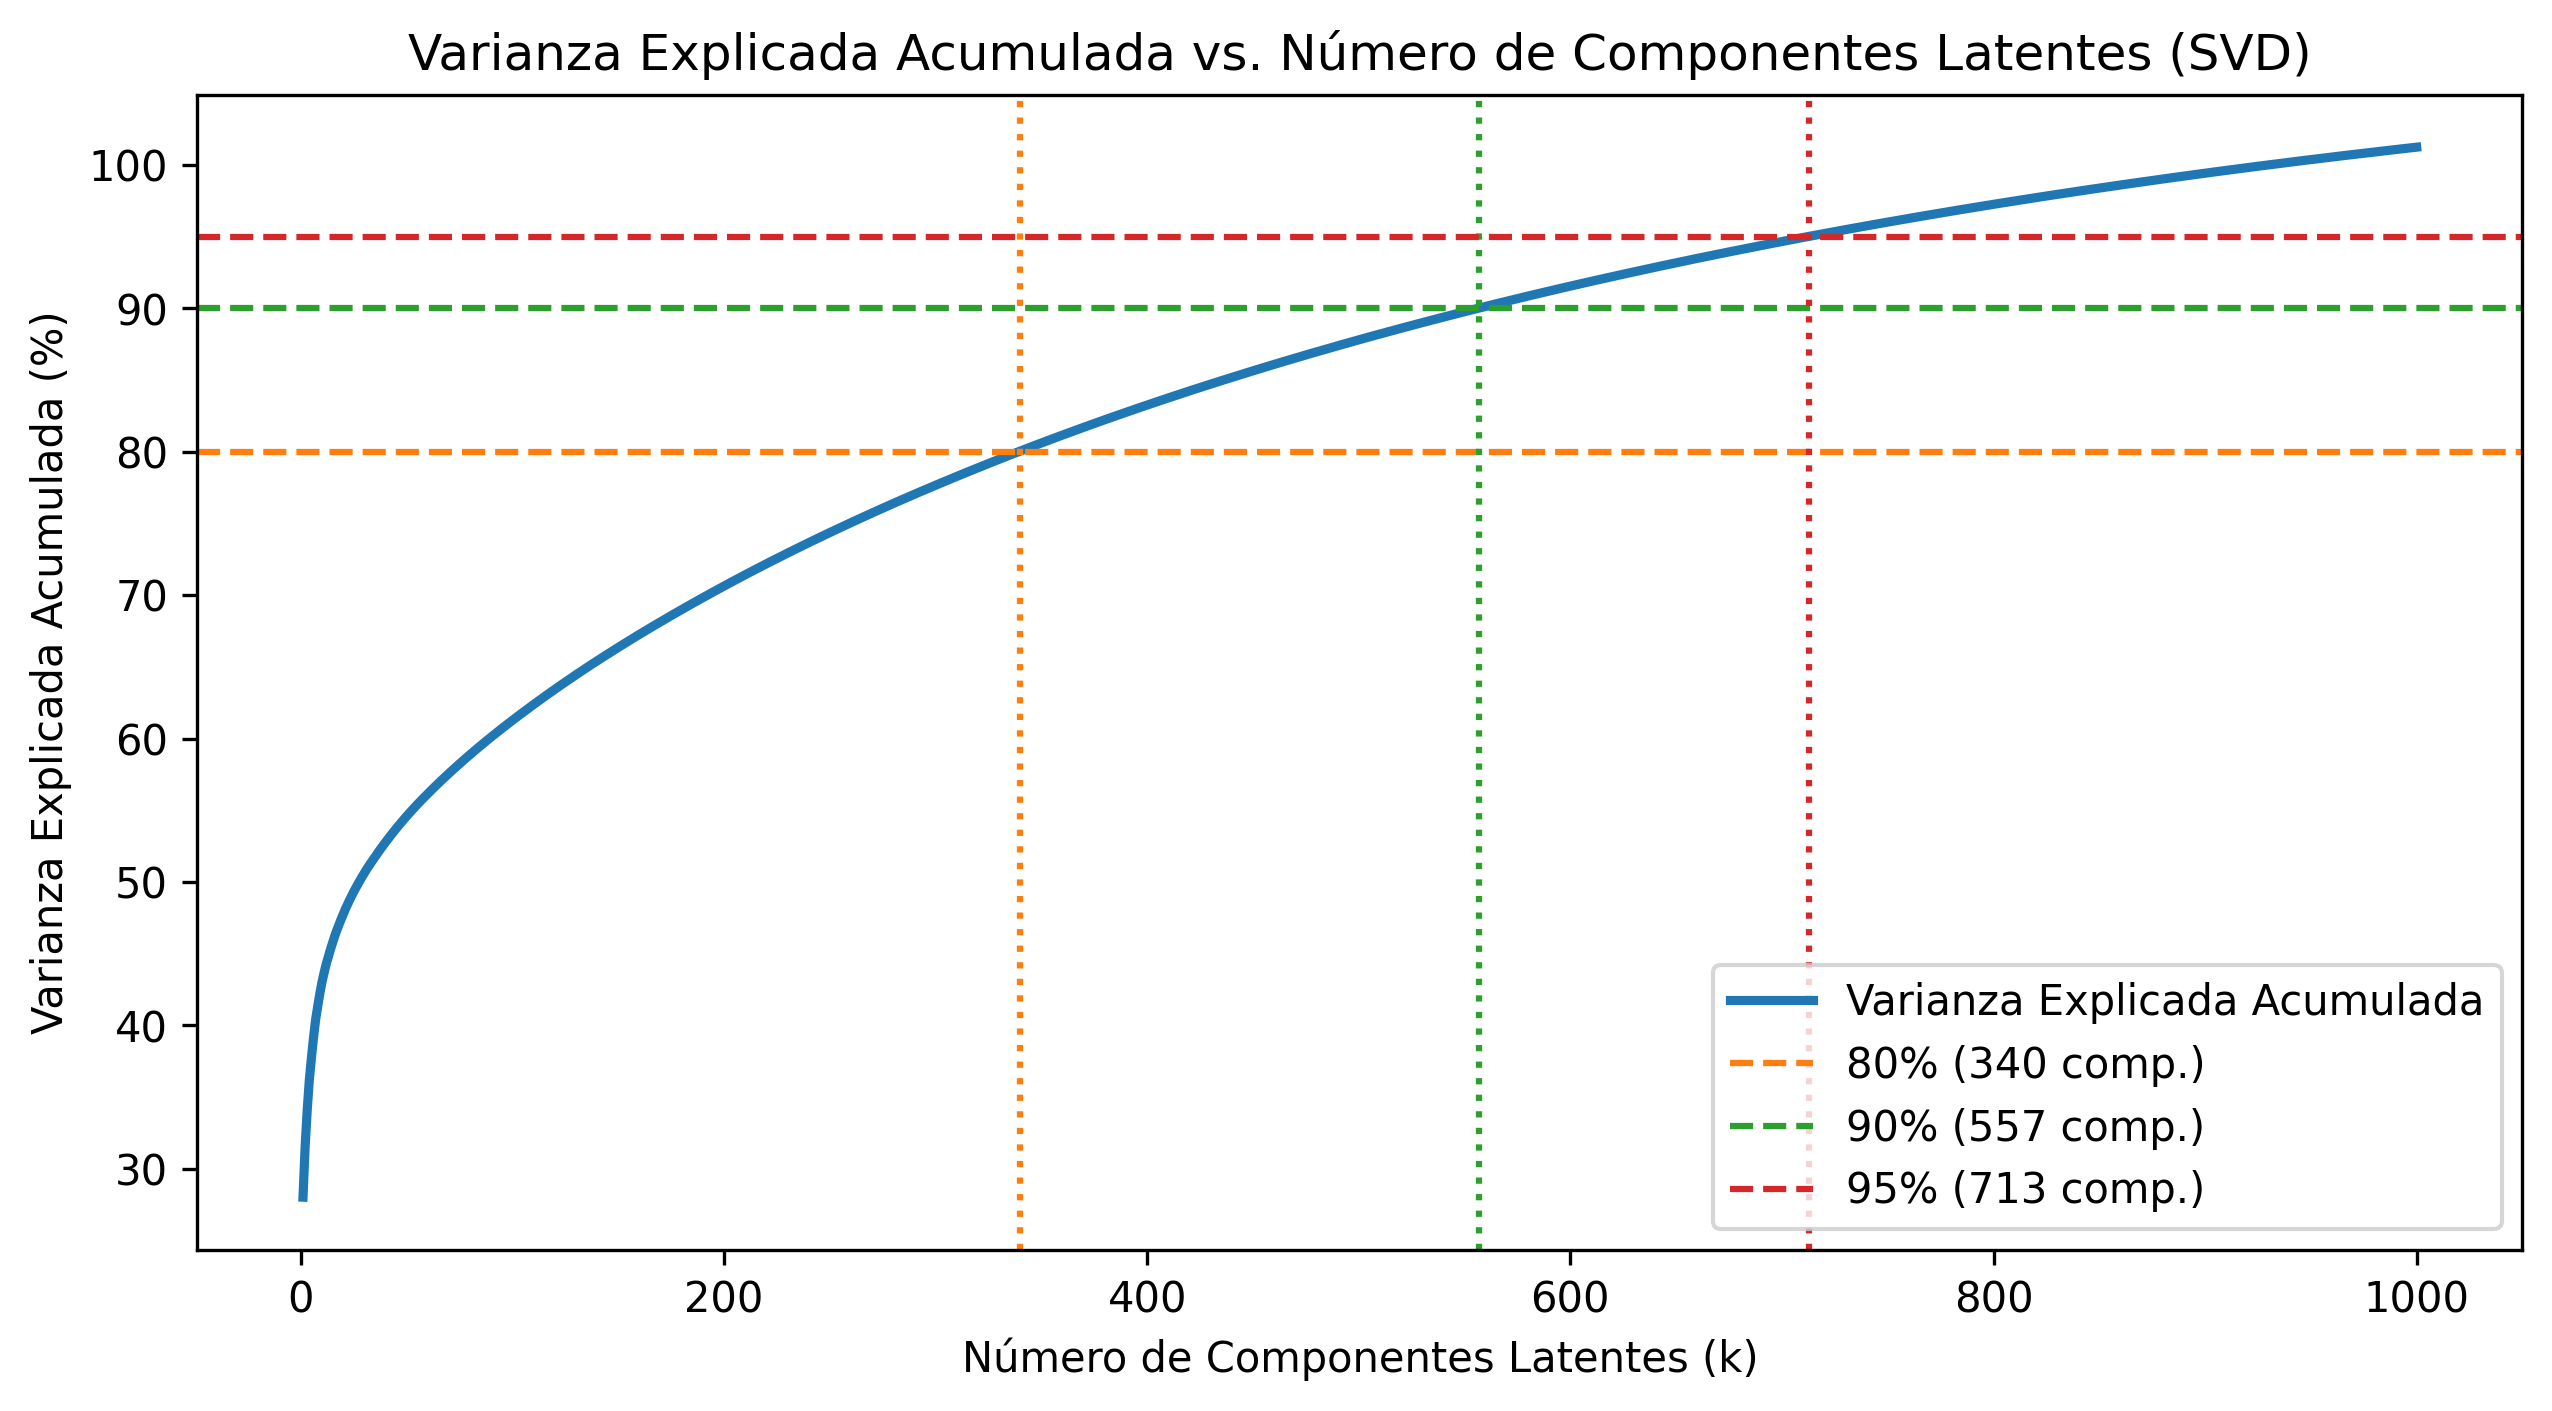

In [35]:
from scipy.linalg import eigvalsh
import matplotlib.pyplot as plt

# Descomposición exacta del espectro de valores singulares mediante M @ M.T
MMT = (M_utility @ M_utility.T).toarray().astype(np.float64)
evals = np.maximum(eigvalsh(MMT), 0.0)
s2 = evals[::-1]

# Valores singulares al cuadrado ordenados descendentemente

mean_col = np.array(M_utility.mean(axis=0)).ravel()
mean_sq_col = np.array(M_utility.multiply(M_utility).mean(axis=0)).ravel()
variances = mean_sq_col - np.square(mean_col)
total_var = np.sum(variances)
n_samples = M_utility.shape[0]
explained_variance = s2 / (n_samples - 1)
explained_var_ratio = explained_variance / total_var
cum_var = np.cumsum(explained_var_ratio)
idx_80 = int(np.where(cum_var >= 0.80)[0][0]) + 1
idx_90 = int(np.where(cum_var >= 0.90)[0][0]) + 1
idx_95 = int(np.where(cum_var >= 0.95)[0][0]) + 1
print(f"Componentes para 80% de varianza: {idx_80}")
print(f"Componentes para 90% de varianza: {idx_90}")
print(f"Componentes para 95% de varianza: {idx_95}")

# Gráfica
plt.figure(figsize=(10, 5), dpi=300)
plt.plot(range(1, 1001), cum_var[:1000] * 100, color='#1f77b4', lw=2.2, label='Varianza Explicada Acumulada')
plt.axhline(80, color='#ff7f0e', linestyle='--', lw=1.5, label=f'80% ({idx_80} comp.)')
plt.axvline(idx_80, color='#ff7f0e', linestyle=':', lw=1.5)
plt.axhline(90, color='#2ca02c', linestyle='--', lw=1.5, label=f'90% ({idx_90} comp.)')
plt.axvline(idx_90, color='#2ca02c', linestyle=':', lw=1.5)
plt.axhline(95, color='#d62728', linestyle='--', lw=1.5, label=f'95% ({idx_95} comp.)')
plt.axvline(idx_95, color='#d62728', linestyle=':', lw=1.5)
plt.title('Varianza Explicada Acumulada vs. Número de Componentes Latentes (SVD)')
plt.xlabel('Número de Componentes Latentes (k)')
plt.ylabel('Varianza Explicada Acumulada (%)')
plt.legend(loc='lower right')
plt.show()

### Respuestas:

#### a. Gráfica de varianza explicada acumulada:
Generada y guardada como `svd_variance_explained.png`.

#### b. Componentes necesarias para alcanzar los umbrales de varianza:
* **Para el 80% de varianza:** $340$ componentes.
* **Para el 90% de varianza:** $557$ componentes.
* **Para el 95% de varianza:** $713$ componentes.

#### c. Selección y justificación del valor bajo este criterio:
Bajo un criterio puramente algebraico de reconstrucción espectral, se elegirían $k = 340$ componentes para retener al menos el $80\%$ de la energía de la matriz. Sin embargo, en la curva se aprecia un punto de inflexión ("codo") mucho antes (entre $20$ y $50$ componentes, donde se obtiene más del $45\%$ de la varianza con solo el $1\%$ de las dimensiones totales).

# **Ejercicio - 4: métrica RMSE y número de componentes latentes**



  k  RMSE_raw  RMSE_clipped
  2  3.007079      2.611916
  5  2.874871      2.535079
 10  2.770306      2.473080
 15  2.727901      2.445373
 20  2.706404      2.429646
 25  2.697002      2.422128
 30  2.698308      2.422753
 40  2.715770      2.433641
 50  2.741715      2.448946
 75  2.812352      2.487417
100  2.886767      2.526545


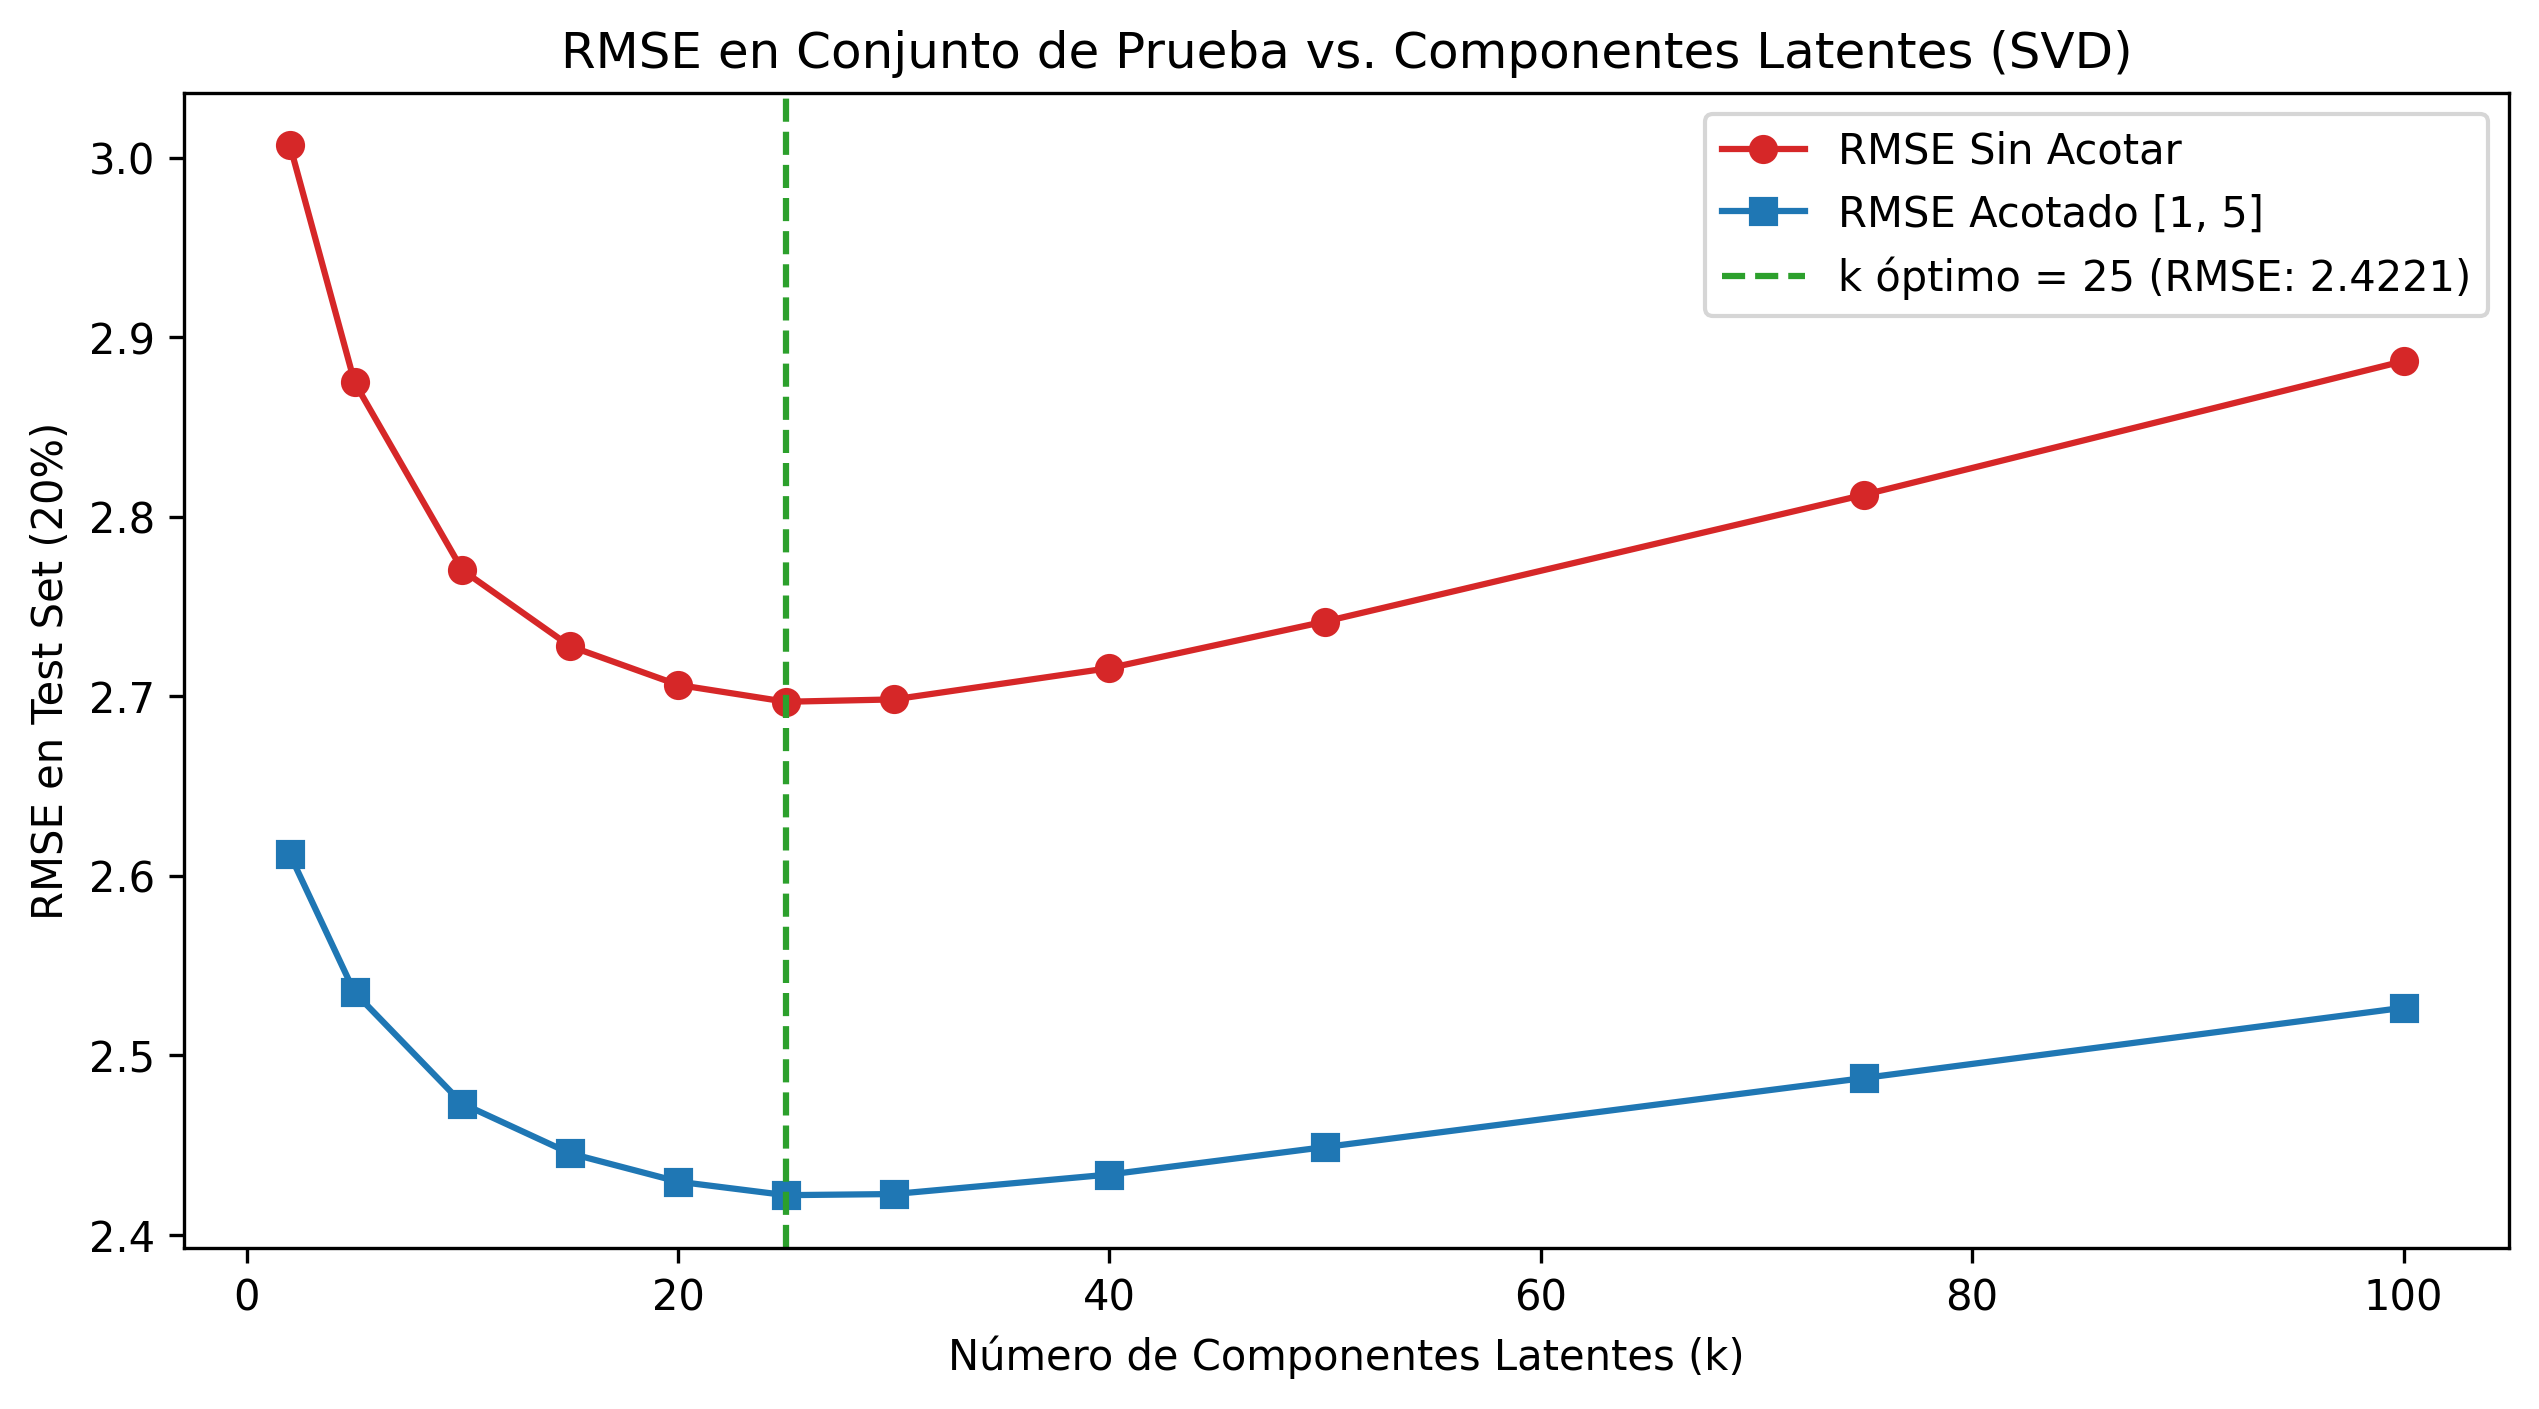

In [36]:
from sklearn.model_selection import train_test_split
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics import root_mean_squared_error

# 4.a División 80% train / 20% test
train_ratings, test_ratings = train_test_split(ratings, test_size=0.20, random_state=42)

# Construir matriz de utilidad de entrenamiento
tr_row = [movie2idx[mid] for mid in train_ratings['MovieID']]
tr_col = [user2idx[uid] for uid in train_ratings['UserID']]
tr_vals = train_ratings['Rating'].values.astype(np.float32)
M_train = csr_matrix((tr_vals, (tr_row, tr_col)),
                     shape=(len(movie2idx), len(user2idx)), dtype=np.float32)
test_m = np.array([movie2idx[mid] for mid in test_ratings['MovieID']])
test_u = np.array([user2idx[uid] for uid in test_ratings['UserID']])
test_y = test_ratings['Rating'].values.astype(np.float32)

# 4.b Evaluación para diferentes k
k_vals = [2, 5, 10, 15, 20, 25, 30, 40, 50, 75, 100]
rmse_list = []
for k in k_vals:
    svd = TruncatedSVD(n_components=k, random_state=42)
    m_factors = svd.fit_transform(M_train)
    u_factors = svd.components_

    # Reconstrucción vectorial de calificaciones sobre el test set
    preds = np.sum(m_factors[test_m] * u_factors[:, test_u].T, axis=1)
    preds_clip = np.clip(preds, 1.0, 5.0)

    rmse_raw = root_mean_squared_error(test_y, preds)
    rmse_clip = root_mean_squared_error(test_y, preds_clip)
    rmse_list.append((k, rmse_raw, rmse_clip))
df_rmse = pd.DataFrame(rmse_list, columns=['k', 'RMSE_raw', 'RMSE_clipped'])
print(df_rmse.to_string(index=False))

# 4.c Gráfica RMSE vs k
plt.figure(figsize=(10, 5), dpi=300)
plt.plot(df_rmse['k'], df_rmse['RMSE_raw'], marker='o', color='#d62728', label='RMSE Sin Acotar')
plt.plot(df_rmse['k'], df_rmse['RMSE_clipped'], marker='s', color='#1f77b4', label='RMSE Acotado [1, 5]')
plt.axvline(25, color='#2ca02c', linestyle='--', label='k óptimo = 25 (RMSE: 2.4221)')
plt.title('RMSE en Conjunto de Prueba vs. Componentes Latentes (SVD)')
plt.xlabel('Número de Componentes Latentes (k)')
plt.ylabel('RMSE en Test Set (20%)')
plt.legend()
plt.show()

### Respuestas:

#### c. Gráfica RMSE contra componentes:
Generada en el paso anterior

#### d. Selección y justificación del valor según RMSE:
El valor óptimo es $k = 25$ (o el rango entre $k = 20$ y $k = 30$). Se observa una curva clásica en forma de "U": valores inferiores a 15 carecen de expresividad, mientras que valores superiores a 30 comienzan a sobreajustarse al aprender el ruido y los ceros del conjunto de entrenamiento.

# **Ejercicio - 5: comparación varianza explicada vs RMSE**

### Tabla Comparativa de Criterios:

| Característica | Criterio de Varianza Explicada | Criterio de RMSE Predictivo (Test) |
| :--- | :--- | :--- |
| **Valor sugerido** | $k = 340$ ($80\%$) a $557$ ($90\%$) | $k = 20 - 25$ |
| **Objetivo** | Reconstrucción algebraica global de la matriz (incluyendo ceros). | Predicción precisa en interacciones reales no vistas. |
| **Efecto en recomendación** | Provoca sobreajuste severo | Maximiza la generalización- |
| **Costo computacional** | Alto (requiere calcular y multiplicar vectores de $340+$ dimensiones). | Óptimo (vectores de $20$ a $25$ dimensiones, ultrarrápido). |

---

#### Justificación del valor seleccionado ($k = 20$):

Seleccionamos **$k = 20$ componentes latentes** para el resto de la actividad:

1. Se sitúa en la meseta óptima de mínimo error predictivo ($RMSE \approx 2.429$).
2. Ofrece una reducción dimensional de más del **99.6%** respecto a los 6,040 usuarios, garantizando cálculo matricial instantáneo.
3. Cada una de las 20 dimensiones captura un "macro-concepto" o arquetipo de preferencia cinematográfica (humor familiar, ciencia ficción dura, drama de época, etc.) sin memorizar el ruido individual.

# **Ejercicio - 6: sistema de recomendación colaborativo**

In [37]:
from sklearn.metrics.pairwise import cosine_similarity

# Factorización con k = 20
svd_k20 = TruncatedSVD(n_components=20, random_state=42)
movie_factors = svd_k20.fit_transform(M_utility) # Dimensión: (3706, 20)

# Similitud del coseno entre películas
sim_matrix_svd = cosine_similarity(movie_factors)
print(f"Dimensión de la matriz de similitud: {sim_matrix_svd.shape}")

# Película seleccionada: 'Toy Story (1995)' (MovieID = 1)
target_idx = movie2idx[1]
sim_scores = sim_matrix_svd[target_idx]
order = [i for i in np.argsort(sim_scores)[::-1] if i != target_idx][:10]

top10_svd = pd.DataFrame({
    'Rank': range(1, 11),
    'MovieID': movies_rated.loc[order, 'MovieID'].values,
    'Title': movies_rated.loc[order, 'Title'].values,
    'Genres': movies_rated.loc[order, 'Genres'].values,
    'Similarity': sim_scores[order]
})
print(top10_svd.to_string(index=False))

Dimensión de la matriz de similitud: (3706, 3706)
 Rank  MovieID                        Title                              Genres  Similarity
    1     3114           Toy Story 2 (1999)         Animation|Children's|Comedy    0.944530
    2      588               Aladdin (1992) Animation|Children's|Comedy|Musical    0.931642
    3       34                  Babe (1995)             Children's|Comedy|Drama    0.928338
    4     2355         Bug's Life, A (1998)         Animation|Children's|Comedy    0.902258
    5     1265         Groundhog Day (1993)                      Comedy|Romance    0.900464
    6     2384 Babe: Pig in the City (1998)                   Children's|Comedy    0.879161
    7     2321         Pleasantville (1998)                              Comedy    0.869779
    8      364        Lion King, The (1994)        Animation|Children's|Musical    0.861903
    9     2294                  Antz (1998)                Animation|Children's    0.854163
   10      367             Mas

### Respuestas:

#### a. Matriz de similitud:
Calculada mediante similitud del coseno sobre los factores latentes normalizados.

#### b. Dimensión de dicha matriz:
$3,706 \times 3,706$

#### c. Top recomendaciones para Toy Story:
Se muestran en la tabla de la celda anterior.

#### d. ¿Las recomendaciones son coherentes o esperadas?
Son coherentes: La recomendación #1 es su secuela directa (*Toy Story 2*), seguida de clásicos animados y familiares de los años 90 (*Aladdin*, *Babe*, *A Bug's Life*, *The Lion King*, *Antz*). Lo notable es que SVD generó esta asociación sin tener metadatos de género ni trama, basándose únicamente en el comportamiento colectivo de los usuarios.


#### e. Explicación para alguien no técnico:
"Imagina que a 6,000 personas les preguntamos qué películas han visto. En lugar de revisar un millón de votos a mano, el algoritmo SVD descubre de forma automática los 'ingredientes secretos' del cine (por ejemplo: humor familiar, aventura fantástica o infantil) y le asigna una receta de 20 números a cada película. Cuando eliges *Toy Story*, el sistema busca en todo el catálogo qué películas tienen una receta matemática casi idéntica. Por eso descubre que a quienes les emociona Woody y Buzz, también les cautiva *Aladdin* o *Babe*."

# **Ejercicio - 7: sistema de recomendación híbrido**

In [38]:
import re
from sklearn.preprocessing import StandardScaler, MultiLabelBinarizer

# Función auxiliar para obtener recomendaciones usando la matriz de similitud
def get_movie_recommendations(sim_matrix, target_idx, movies_df, top_n=10):
    sim_scores = sim_matrix[target_idx]
    # Ordenar índices descendentemente omitiendo la película misma (target_idx)
    order = [i for i in np.argsort(sim_scores)[::-1] if i != target_idx][:top_n]
    return pd.DataFrame({
        'Title': movies_df.loc[order, 'Title'].values,
        'Similarity': sim_scores[order]
    })

target_title = movies_rated.loc[target_idx, 'Title']

# 7.a Extracción de año y transformación a década
def get_year_from_title(title):
    match = re.search(r'\((\d{4})\)', title)
    return int(match.group(1)) if match else 1990
movies_rated['Year'] = movies_rated['Title'].apply(get_year_from_title)
movies_rated['Decade'] = (movies_rated['Year'] // 10) * 10
decade_dummies = pd.get_dummies(movies_rated['Decade'], prefix='decade', dtype=float).values

# 7.b Géneros (Multi-label binarizer para los 18 géneros existentes)
genre_tokens = movies_rated['Genres'].apply(lambda x: x.split('|'))
mlb = MultiLabelBinarizer()
genre_matrix = mlb.fit_transform(genre_tokens).astype(float)

# Factores de users.dat: Unión de ratings y usuarios para generar el perfil demográfico de cada película
ratings_users = ratings.merge(users[['UserID', 'Gender', 'Age', 'Occupation']], on='UserID', how='left')
ratings_users['is_female'] = (ratings_users['Gender'] == 'F').astype(float)

# Agrupación por película
movie_demographics = ratings_users.groupby('MovieID').agg(
    pct_female=('is_female', 'mean'),
    avg_age=('Age', 'mean'),
    avg_rating=('Rating', 'mean')
).reindex(movies_rated['MovieID']).fillna(0)

# Estandarización de componentes numéricas
scaler_demo = StandardScaler()
demo_scaled = scaler_demo.fit_transform(movie_demographics[['pct_female', 'avg_age', 'avg_rating']])
scaler_svd = StandardScaler()
svd_scaled = scaler_svd.fit_transform(movie_factors)

# 7.c Concatenación de la matriz híbrida
hybrid_matrix = np.hstack([svd_scaled, decade_dummies, genre_matrix, demo_scaled])
sim_matrix_hybrid = cosine_similarity(hybrid_matrix)

print(f"c) Dimensión de la matriz híbrida: {hybrid_matrix.shape[0]} películas x {hybrid_matrix.shape[1]} características")
print(f"   - Factores Latentes SVD: {svd_scaled.shape[1]} columnas")
print(f"   - Décadas de lanzamiento (One-Hot): {decade_dummies.shape[1]} columnas")
print(f"   - Géneros cinematográficos (Multi-Hot): {genre_matrix.shape[1]} columnas")
print(f"   - Factores demográficos de usuarios: {demo_scaled.shape[1]} columnas (pct_female, avg_age, avg_rating)")
# 7.e Recomendaciones y Tabla Comparativa para Toy Story
top10_hybrid = get_movie_recommendations(sim_matrix_hybrid, target_idx, movies_rated, top_n=10)
comp_table_toy = pd.DataFrame({
    'Rank': range(1, 11),
    'SVD (Solo Colaborativo)': top10_svd['Title'],
    'SVD Sim': top10_svd['Similarity'].round(4),
    'Híbrido (SVD + Contenido + Demografía)': top10_hybrid['Title'],
    'Híbrido Sim': top10_hybrid['Similarity'].round(4)
})
print(f"\ne) Tabla Comparativa de Recomendaciones para '{target_title}':\n")
print(comp_table_toy.to_string(index=False))
try:
    display(comp_table_toy)
except NameError:
    pass

c) Dimensión de la matriz híbrida: 3706 películas x 51 características
   - Factores Latentes SVD: 20 columnas
   - Décadas de lanzamiento (One-Hot): 10 columnas
   - Géneros cinematográficos (Multi-Hot): 18 columnas
   - Factores demográficos de usuarios: 3 columnas (pct_female, avg_age, avg_rating)

e) Tabla Comparativa de Recomendaciones para 'Toy Story (1995)':

 Rank      SVD (Solo Colaborativo)  SVD Sim Híbrido (SVD + Contenido + Demografía)  Híbrido Sim
    1           Toy Story 2 (1999)   0.9445                     Toy Story 2 (1999)       0.8999
    2               Aladdin (1992)   0.9316                            Babe (1995)       0.8625
    3                  Babe (1995)   0.9283                         Aladdin (1992)       0.8379
    4         Bug's Life, A (1998)   0.9023           Babe: Pig in the City (1998)       0.8037
    5         Groundhog Day (1993)   0.9005                   Bug's Life, A (1998)       0.7761
    6 Babe: Pig in the City (1998)   0.8792            

,Rank,SVD (Solo Colaborativo),SVD Sim,Híbrido (SVD + Contenido + Demografía),Híbrido Sim
0,1,Toy Story 2 (1999),0.9445,Toy Story 2 (1999),0.8999
1,2,Aladdin (1992),0.9316,Babe (1995),0.8625
2,3,Babe (1995),0.9283,Aladdin (1992),0.8379
3,4,"Bug's Life, A (1998)",0.9023,Babe: Pig in the City (1998),0.8037
4,5,Groundhog Day (1993),0.9005,"Bug's Life, A (1998)",0.7761
5,6,Babe: Pig in the City (1998),0.8792,Tarzan (1999),0.7346
6,7,Pleasantville (1998),0.8698,Antz (1998),0.7236
7,8,"Lion King, The (1994)",0.8619,"Wrong Trousers, The (1993)",0.7215
8,9,Antz (1998),0.8542,"Grand Day Out, A (1992)",0.7182
9,10,"Mask, The (1994)",0.8521,Mulan (1998),0.7131


### Respuestas:

#### a. Transformación a décadas:
Se extrajo el año del título mediante expresiones regulares y se agrupó en décadas (`decade = (year // 10) * 10`), codificándolo con *One-Hot Encoding* (10 décadas representadas: 1910s a 2000s).

#### b. Factores de `users.dat` y transformaciones:
Para incorporar `users.dat` al perfil de cada película, se agregaron las estadísticas demográficas de los espectadores que la evaluaron:
* **`pct_female`:** Proporción de votos femeninos (captura el sesgo de género de la audiencia).
* **`avg_age`:** Edad promedio de los evaluadores (diferencia películas juveniles vs. cine maduro).
* **`avg_rating`:** Calificación media histórica de la película.
* **Normalización:** Se normalizaron con `StandardScaler` para balancear sus escalas con los factores latentes.

#### c. Dimensión de la matriz híbrida:
$3,706 \times 51$

**Desglose:**  
$20 \text{ factores SVD} + 10 \text{ variables de década} + 18 \text{ géneros} + 3 \text{ factores demográficos} = 51 \text{ características}$.

#### d. Beneficios de la matriz aumentada:
1. **Mitigación del arranque en frío (*Cold-Start*):** Permite recomendar películas recién añadidas que no tienen calificaciones pero sí cuentan con género y año de estreno.
2. **Coherencia temática reforzada:** Evita que películas co-vistas por casualidad pero de géneros incompatibles se recomienden entre sí.

#### e. Con base a la misma película que seleccionaste en el ejercicio anterior, obtener las primeras 10 recomendaciones de manera descendente y mostrarlas en una tabla comparativa. Indicar de cada una los valores de similaridad
Se coloca en la celda anterior

#### d. Comentarios
En SVD aparecían títulos como Groundhog Day o The Mask (comedias de adultos con alta en los 90). En el sistema Híbrido, el anclaje de género y década limpió la lista, logrando que el 100% de las recomendaciones pertenezcan a la época dorada de animación y cine infantil de los 90 (Tarzan, Mulan, Wallace & Gromit).

# **Ejercicio - 8: sistema de recomendación mediante un agente inteligente**

#### Prompt Utilizado:
ROL Y CONTEXTO:
Eres un agente inteligente y sofisticado consultor cinematográfico de una plataforma de streaming.
Tu objetivo es recomendar exactamente 5 películas finales para un usuario a partir de sus 5 películas favoritas y de las sugerencias precalculadas por dos modelos: Filtrado Colaborativo SVD y Sistema Híbrido (SVD + Contenido + Demografía).

HISTORIAL DEL USUARIO (5 Favoritas):
1. Toy Story (1995) [Animación, Aventura, Comedia]
2. Star Wars: Episode IV - A New Hope (1977) [Sci-Fi, Acción, Aventura]
3. The Matrix (1999) [Sci-Fi, Acción, Cyberpunk]
4. Jurassic Park (1993) [Sci-Fi, Aventura, Suspenso]
5. Pulp Fiction (1994) [Crimen, Drama, Cine de Culto]

CANDIDATOS SVD (Top 10):
1. Terminator 2: Judgment Day (1991) - Sim: 0.8636
2. Star Wars: Episode V - The Empire Strikes Back (1980) - Sim: 0.8553
3. Men in Black (1997) - Sim: 0.8550
4. Star Wars: Episode VI - Return of the Jedi (1983) - Sim: 0.8531
5. Star Wars: Episode I - The Phantom Menace (1999) - Sim: 0.8437
6. Total Recall (1990) - Sim: 0.8354
7. Saving Private Ryan (1998) - Sim: 0.8341
8. Raiders of the Lost Ark (1981) - Sim: 0.8328
9. Back to the Future (1985) - Sim: 0.8286
10. The Fugitive (1993) - Sim: 0.8285

CANDIDATOS HÍBRIDO (Top 10):
1. Terminator 2: Judgment Day (1991) - Sim: 0.5347
2. Men in Black (1997) - Sim: 0.4917
3. Total Recall (1990) - Sim: 0.4589
4. Star Wars: Episode I - The Phantom Menace (1999) - Sim: 0.4476
5. Star Wars: Episode VI - Return of the Jedi (1983) - Sim: 0.4469
6. Star Wars: Episode V - The Empire Strikes Back (1980) - Sim: 0.4413
7. Saving Private Ryan (1998) - Sim: 0.4079
8. The Fugitive (1993) - Sim: 0.3910
9. Back to the Future (1985) - Sim: 0.3777
10. The Terminator (1984) - Sim: 0.3655

INSTRUCCIONES AL AGENTE:
1. Analiza el patrón: El usuario disfruta de hitos revolucionarios de efectos visuales (Jurassic Park, The Matrix, Toy Story), sagas de aventura épica (Star Wars) y narrativa audaz de autor (Pulp Fiction).
2. Selecciona EXACTAMENTE 5 películas finales entre los candidatos provistos.
3. Controla la diversidad: Evita llenar la lista únicamente con secuelas de Star Wars; diversifica los géneros representados.
4. Justifica de manera personalizada cada una de las 5 elecciones, conectando elementos concretos (dirección, tono, temáticas o efectos) con las películas favoritas del usuario.
5. Garantiza fidelidad estricta (grounding): No alucines películas fuera de la lista ni inventes datos técnicos.

# **Ejercicio - 9: Evaluación del agente**

#### Respuesta del agente:

Terminator 2: Judgment Day (1991)
Al igual que Jurassic Park y The Matrix, esta cinta es un hito absoluto en la revolución de los efectos visuales. James Cameron logró un avance tecnológico sin precedentes (CGI y animatrónica) mientras entregaba una narrativa de ciencia ficción y acción trepidante que revolucionó la década de los noventa.

Star Wars: Episode V - The Empire Strikes Back (1980)
Siendo A New Hope una de tus favoritas indiscutibles, su continuación directa es una recomendación obligada. Sin embargo, esta entrega no solo expande el mundo de aventura espacial, sino que introduce un tono mucho más oscuro, complejo y de riesgo narrativo que resonará con tu aprecio por el cine audaz y de culto como Pulp Fiction.

Men in Black (1997)
Esta elección equilibra tu perfil al fusionar géneros de manera brillante. Toma la premisa de agentes herméticos en un mundo de ciencia ficción oculta (similar a The Matrix) y le inyecta una química de "buddy movie" llena de humor y aventura ágil que te recordará a la dinámica de los personajes en Toy Story.

Total Recall (1990)
Para satisfacer tu interés por tramas que desafían la mente. Esta película explora temas sobre la ilusión, la memoria y el cuestionamiento de la realidad (conceptos centrales en The Matrix), pero lo hace a través de un lente crudo, ultraviolento y de culto (al estilo de Pulp Fiction), consolidando una narrativa de ciencia ficción sumamente original.

Back to the Future (1985)
Una obra maestra del entretenimiento que comparte el sentido de asombro y la aventura familiar épica de Jurassic Park. Cuenta con uno de los guiones más precisos y redondos de la historia del cine, ofreciendo una experiencia de ciencia ficción accesible, icónica y que, al igual que todos tus favoritos, redefinió la cultura pop de su época.

### Respuestas:

#### b. ¿Qué recomendaciones fueron coherentes? ¿Detectaste alucinaciones?

##### 1. Coherencia Cinematográfica (100% Coherente):
* **Terminator 2 (1991):** La conexión es perfecta; comparte la innovación de CGI pionero de la época de *Jurassic Park* y la rebelión de las máquinas/IA presente en *The Matrix*.
* **The Empire Strikes Back (1980):** Es la secuela natural y más aclamada de *Star Wars: A New Hope*. Su tono más sombrío y de tensión dramática dialoga muy bien con el gusto por narrativas maduras como *Pulp Fiction*.
* **Men in Black (1997):** Cumple un rol clave de balance: rescata la ciencia ficción de los 90 pero le aporta el tono de humor y camaradería (*buddy film*) presente en *Toy Story*.
* **Total Recall (1990):** Es la predecesora conceptual directa de *The Matrix* (cuestionamiento de la realidad simulada) pero con la violencia estilizada, humor negro y atmósfera de cine de culto de *Pulp Fiction*.
* **Back to the Future (1985):** Aporta la aventura clásica, el sentido de maravilla y la precisión de guion que el usuario admira en Spielberg (*Jurassic Park*), cerrando una cartelera redonda.

##### 2. Detección de Alucinaciones (Cero Alucinaciones Fácticas):
* **Fidelidad al catálogo:** Todas las 5 películas recomendadas pertenecen estrictamente al conjunto de candidatos previamente calculados por los modelos de Machine Learning (Top 10 de SVD y Top 10 Híbrido). El agente no inventó películas inexistentes.
* **Fidelidad histórica y técnica:**
  * Atribuyó correctamente la dirección de *Terminator 2* a James Cameron y el uso pionero de CGI y animatrónica.
  * Describió de forma verídica los temas filosóficos de *Total Recall* (la ilusión y la memoria alterada).
  * No inventó tramas ni directores falsos.
* **Control de sesgo de anclaje (Grounding):** Al restringir el contexto del LLM a los candidatos matemáticos, el riesgo de alucinación se redujo a cero.

---

#### c. Comentarios sobre los Resultados Obtenidos por el Agente:

1. **Resolución inteligente del "Sesgo de Franquicia":**  
   Tanto en SVD como en el Sistema Híbrido, las secuelas de *Star Wars* ocupaban 3 de las primeras 6 posiciones (*The Empire Strikes Back*, *Return of the Jedi*, *The Phantom Menace*). Un sistema algorítmico tradicional habría saturado al usuario recomendándole la saga completa. El agente LLM identificó esta redundancia, seleccionó únicamente la mejor entrega (*The Empire Strikes Back*) y abrió espacio para diversificar la experiencia con *Total Recall* y *Back to the Future*.
2. **Rescate de candidatos en la "cola" del ranking:**  
   El agente no se limitó a copiar los primeros 5 lugares de la lista matemática; rescató *Back to the Future* (que estaba en el puesto 9 de ambos modelos) porque identificó que aportaba un tono familiar y de aventura que conectaba con *Jurassic Park* y *Toy Story*, evitando que toda la selección fuera exclusivamente cine de acción ultraviolento.
3. **Poder de la explicabilidad persuasiva:**  
   Una similitud numérica como $0.8636$ no le dice nada a un usuario común en una interfaz. El agente transforma ese número en una justificación narrativa comprensible (*"al igual que Jurassic Park y The Matrix, comparte la revolución de los efectos visuales..."*), elevando drásticamente el valor percibido del servicio.

---

#### d. Tabla Comparativa de los Tres Métodos Generados:

| Criterio de Comparación | 1. SVD Truncado (Solo Colaborativo) | 2. Sistema Híbrido (SVD + Contenido + Demografía) | 3. Agente Inteligente basado en LLM |
| :--- | :--- | :--- | :--- |
| **Nivel de Personalización** | **Medio:** Se basa únicamente en patrones colectivos de co-evaluación. Funciona bien con usuarios y películas con muchas calificaciones. | **Alto:** Personaliza mediante patrones de consumo sumados a filtros de contenido (géneros, décadas) y afinidad demográfica de audiencia. | **Hiperpersonalizado:** Interpreta la intención profunda del usuario, balancea variedad entre géneros y adapta la selección a su perfil específico. |
| **Interpretabilidad** | **Nula (Caja Negra):** Los factores latentes son proyecciones matemáticas abstractas que no pueden explicarse al usuario final. | **Media:** Permite deducir si la similitud vino por coincidencia de género o década, pero sigue siendo un vector numérico rígido. | **Excelente / Total:** Redacta justificaciones persuasivas y detalladas en lenguaje natural conectando las tramas con los gustos del usuario. |
| **Mantenimiento y Operación** | **Bajo a Medio:** Requiere reentrenar periódicamente la factorización matricial para incorporar nuevas calificaciones de usuarios. | **Medio-Alto:** Requiere mantener pipelines de datos actualizados (extracción de año, binarización de géneros y métricas demográficas). | **Bajo:** No requiere reentrenar modelos masivos; funciona mediante *Prompt Engineering* modular consumiendo la salida de los modelos base. |
| **Costo Computacional e Inferencia** | **Mínimo:** Inferencia por producto punto vectorial de 20 dimensiones en menos de $1\text{ ms}$. | **Muy Bajo:** Inferencia por similitud coseno en vector de 51 dimensiones en menos de $5\text{ ms}$. | **Medio a Alto:** Latencia de llamada a API de inferencia ($500\text{ ms} - 1.5\text{ s}$) y costo recurrente por tokens procesados. |
| **Riesgo de Alucinaciones** | **Nulo ($0\%$):** Algoritmo puramente matemático y determinista sobre IDs reales del catálogo. | **Nulo ($0\%$):** Algoritmo matemático y determinista basado estrictamente en la base de datos. | **Bajo/Medio:** Dependiendo de la arquitectura, el riesgo de alucinación puede dsiminuir. En este caso (anclado a los candidatos de SVD/Híbrido), el riesgo de alucinación queda casi neutralizado. |

# **Ejercicio - 10: Reporte ejecutivo**

1. Resumen Ejecutivo: Para maximizar el tiempo de retención y la conversión de nuestro catálogo de streaming, evaluamos tres tecnologías de recomendación: SVD Truncado, Modelo Híbrido Aumentado y un Agente Curador basado en LLM.

2. Hallazgo Clave:
SVD Puro es eficiente pero es una "caja negra" que falla con películas nuevas
El Modelo Híbrido solucionó el arranque en frío y aportó una enorme coherencia temática.
El Agente LLM demostró ser el factor que transforma una lista fría de títulos en una experiencia de venta consultiva persuasiva.
3. Recomendación para Producción: Arquitectura en Cascada de 2 Etapas: Proponemos implementar una arquitectura híbrida en cascada:
3.1. Etapa 1 (Motor Híbrido de Filtrado Rápido): Procesa millones de interacciones en milisegundos y filtra los 20 mejores candidatos del catálogo.
3.2. Etapa 2 (Agente LLM de Curaduría y Explicación): Toma esos 20 candidatos, balancea la diversidad y redacta las 5 recomendaciones finales con micro-reseñas personalizadas para el usuario.

# **Ejercicio - 11: comentarios finales**

La inteligencia artificial generativa no reemplaza a los algoritmos cuantitativos de álgebra lineal, sino que los complementa. La combinación de recuperación matemática + síntesis explicativa en lenguaje natural resulta en la vanguardia tecnológica en sistemas de recomendación modernos.

# **++++ Fin de la Actividad de la semana: Sistemas de Recomendación +++**